# RainGuard: findings and evaluation

Every number here is read from `data/processed/`, produced by `python analysis/run_pipeline.py`.
Rebuild this notebook with `python notebooks/make_findings_notebook.py`.

Evidence kinds follow the app: **observed** (IMD rain), **historical** (official 2026 lists, BMC ward map),
**estimated** (models, geocodes, terrain), **forecast** (third-party).

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROC = Path.cwd().parent / "data" / "processed"
findings = {f["id"]: f for f in json.loads((PROC / "eda_findings.json").read_text(encoding="utf8"))}
wards = pd.read_csv(PROC / "ward_stats.csv")
evaluation = json.loads((PROC / "evaluation.json").read_text())
outlook = json.loads((PROC / "outlook.json").read_text())
allocation = json.loads((PROC / "allocation.json").read_text())
sens = json.loads((PROC / "score_sensitivity.json").read_text())
for f in findings.values():
    print(f"{f['id']}: {f['title']}")

F1: 10 of 15 suburban wards but 2 of 9 island-city wards are in the two highest incident classes - and ward population alone ranks wards with Spearman rho = 0.83
F2: Three official lists name 251 distinct places, but only 16 (6%) appear on more than one list
F3: Monsoon rain is extremely concentrated, and global-model rainfall misses Mumbai's extremes
F4: Terrain (90 m DEM) does not clearly separate listed spots from the rest of their ward
F5: 43 of 97 BMC-listed spots have no dewatering pump recorded against them
F6: After a heavy-rain day, the next day is heavy 43% of the time, against 6% after other monsoon days


## F1: recorded ward incidents mostly follow population

Finding → evidence → so what: the incident map is a reporting/exposure signal, so the app labels it
"mostly follows population" and offers a population-adjusted alternative in the score.

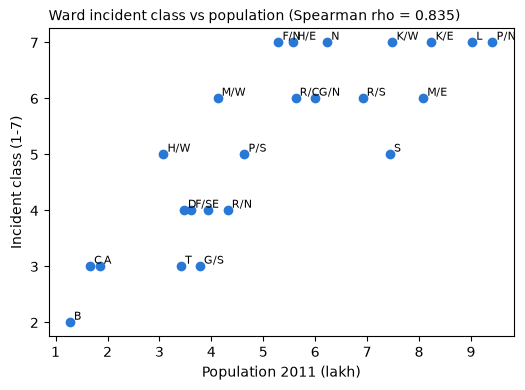

,loo_mae_classes,loo_spearman,permutation_p_value
B0_median,1.917,None,NaN
B1_population,0.732,0.818,0.001
B2_population_area,0.751,0.812,0.001
M1_plus_terrain,0.724,0.817,0.001
M2_plus_listed_spots,0.751,0.812,0.001


In [2]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(wards.population_2011 / 1e5, wards.incident_class, color="#2a78d6")
for r in wards.itertuples():
    ax.annotate(r.ward, (r.population_2011 / 1e5, r.incident_class), fontsize=8, xytext=(3, 2), textcoords="offset points")
ax.set_xlabel("Population 2011 (lakh)"); ax.set_ylabel("Incident class (1-7)")
rho = evaluation["ward_level"]["spearman_population_vs_class"]["rho"]
ax.set_title(f"Ward incident class vs population (Spearman rho = {rho})", loc="left", fontsize=10)
plt.show()
pd.DataFrame(evaluation["ward_level"]["models"]).T[["loo_mae_classes", "loo_spearman", "permutation_p_value"]]

## F2: the three official lists barely overlap

So what: disagreement between agencies is itself an action item (the `list_gap` label).

In [3]:
pd.Series(findings["F2"]["numbers"]["by_source_combination"]).sort_values(ascending=False).to_frame("places")

,places
BMC_FPG_2026,84
MTP_DIVERSIONS_2026,76
BEST_ANNEX_IX_2026,75
BMC_FPG_2026|MTP_DIVERSIONS_2026,8
BEST_ANNEX_IX_2026|MTP_DIVERSIONS_2026,4
BEST_ANNEX_IX_2026|BMC_FPG_2026,3
BEST_ANNEX_IX_2026|BMC_FPG_2026|MTP_DIVERSIONS_2026,1


## F3: the monsoon concentrates the rain

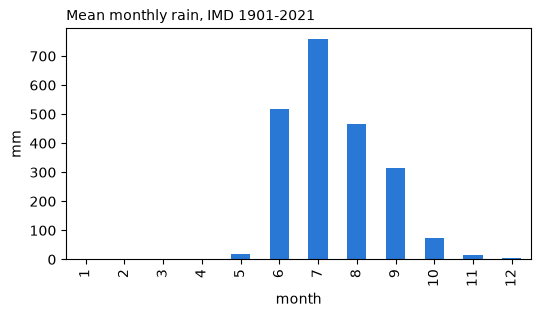

In [4]:
clim = pd.read_csv(PROC / "rainfall_monthly_climatology.csv")
ax = clim.plot.bar(x="month", y="mean", legend=False, color="#2a78d6", figsize=(6, 3))
ax.set_ylabel("mm"); ax.set_title("Mean monthly rain, IMD 1901-2021", loc="left", fontsize=10); plt.show()

## F4: terrain shows no significant signal (a null result)

So what: terrain weight is 0 by default.

In [5]:
pd.DataFrame({k: {"n": v["n"], **v["tpi_pct_in_ward"]} for k, v in evaluation["location_terrain_case_control"].items()}).T

,n,median,mean,share_below_0.5,wilcoxon_p_vs_0.5
point_or_street,92.0,0.443,0.458,0.565,0.17369
area_only,144.0,0.536,0.518,0.479,0.40579


## F5: pump coverage of BMC-listed spots

In [6]:
findings["F5"]["numbers"]

{'bmc_rows': 97,
 'rows_with_pump_listed': 54,
 'rows_without_pump_listed': 43,
 'total_pumps_listed': 82,
 'rows_marked_planning_stage': 4,
 'rows_capacity_incomplete': 12}

## F6 and the heavy-rain outlook: chronological test

Target: tomorrow is a heavy-rain day (IMD >= 64.5 mm in either Mumbai cell). Trained on early years,
chosen on a validation block, tested once on the latest years. This is a rain outlook, not a
waterlogging forecast.

In [7]:
om = outlook["observed_model"]
print("split:", om["split_years"], "chosen:", om["chosen_on_validation"])
pd.DataFrame(om["test"]).T

split: {'train': [1971, 2008], 'validate': [2009, 2016], 'test': [2017, 2025]} chosen: M2_logistic


,brier,brier_skill_vs_climatology,auc,brier_skill_95ci
B0_climatology,0.1122,0.0,0.648,NaN
B1_persistence,0.0992,0.116,0.686,"[0.078, 0.16]"
M1_logistic,0.0882,0.214,0.845,"[0.19, 0.239]"
M2_logistic,0.0875,0.22,0.85,"[0.201, 0.243]"


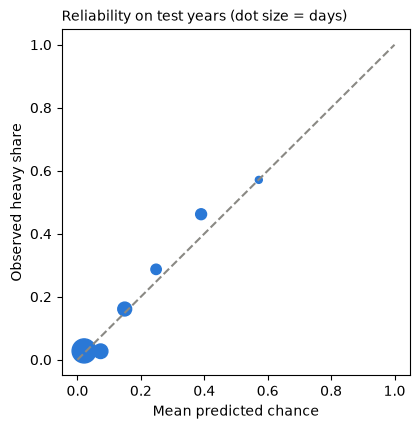

,bin,n,mean_predicted,observed_share
0,0.00-0.05,505,0.021,0.028
1,0.05-0.10,185,0.073,0.027
2,0.10-0.20,168,0.149,0.161
3,0.20-0.30,94,0.248,0.287
4,0.30-0.50,104,0.390,0.462
5,0.50-1.00,42,0.572,0.571


In [8]:
rel = pd.DataFrame(om["test_reliability_chosen"])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], ls="--", color="#8a8984")
ax.scatter(rel.mean_predicted, rel.observed_share, s=rel.n / rel.n.max() * 300, color="#2a78d6")
ax.set_xlabel("Mean predicted chance"); ax.set_ylabel("Observed heavy share")
ax.set_title("Reliability on test years (dot size = days)", loc="left", fontsize=10); plt.show()
rel

In [9]:
fc = outlook["forecast_track_record"]
print(fc["period"], "|", fc["forecast_ge_64_5mm"])
pd.DataFrame(fc["by_forecast_amount"])

2024-06-01 to 2025-09-30, June-September only | {'hits': 5, 'misses': 28, 'false_alarms': 3, 'probability_of_detection': 0.152, 'false_alarm_ratio': 0.375}


,forecast,n_days,heavy_days,heavy_share
0,under 15.6 mm,128,1,0.008
1,15.6-35 mm,80,15,0.188
2,35-64.5 mm,28,12,0.429
3,64.5 mm or more,8,5,0.625


## Inspection plan: how stable is it?

The plan's membership depends on value judgements (weights). The diagnosis labels do not.

In [10]:
print("score top-20 Jaccard vs random weights:", sens["top20_jaccard_default_vs_random_weights"])
print("population-adjusted alternative:", {k: v for k, v in sens["population_adjusted_alternative"].items() if k != "weights"})
print({k: allocation[k] for k in ("k", "cap_per_ward", "wards_in_default_plan", "wards_in_uncapped_top_k", "plan_jaccard_vs_default")})
print("stable core:", allocation["stable_core"])

score top-20 Jaccard vs random weights: {'median': 0.46, 'p5': 0.17}
population-adjusted alternative: {'spearman_vs_default': 0.832, 'top20_jaccard_vs_default': 0.65}
{'k': 20, 'cap_per_ward': 3, 'wards_in_default_plan': 12, 'wards_in_uncapped_top_k': 5, 'plan_jaccard_vs_default': {'median': 0.33, 'p5': 0.21}}
stable core: ['RG-063', 'RG-116', 'RG-204']
